<a href="https://colab.research.google.com/github/tumainkatondo-jpg/VLAN_LABS/blob/main/COU07506_WEEK01_240647431021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

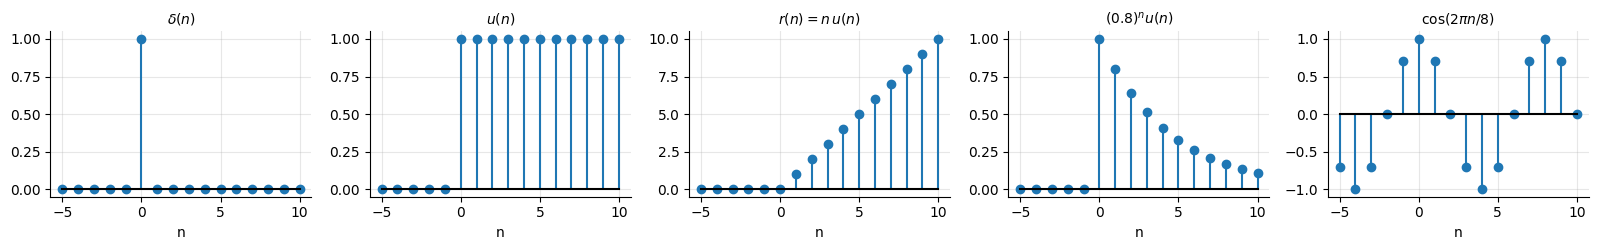

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step  = (n >= 0).astype(float)
ramp  = n * step
expo  = 0.8**n * step
cosn  = np.cos(2 * np.pi * n / 8)

signals = [delta, step, ramp, expo, cosn]
titles = [r"$\delta(n)$",
          r"$u(n)$",
          r"$r(n) = n\,u(n)$",
          r"$(0.8)^n u(n)$",
          r"$\cos(2\pi n/8)$"]

fig, axes = plt.subplots(1, 5, figsize=(16, 2.6))
for ax, x, title in zip(axes, signals, titles):
    ax.stem(n, x, basefmt="k-", linefmt="C0-", markerfmt="C0o")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("n")
    ax.grid(alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

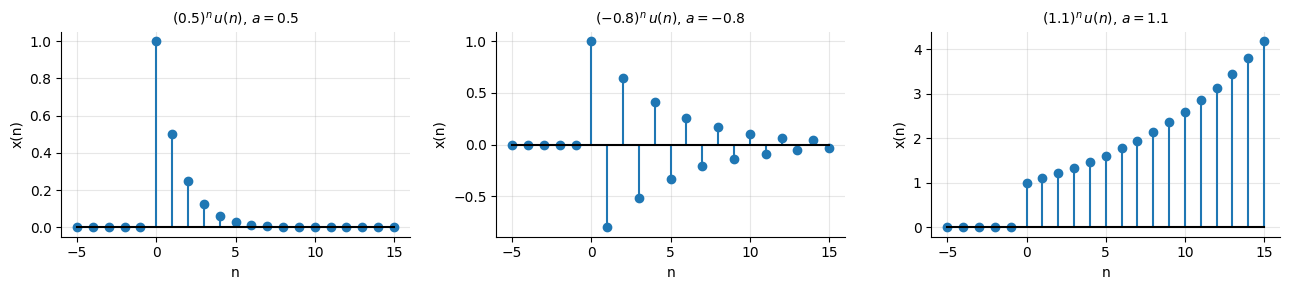

In [ ]:



import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 16)
u = (n >= 0).astype(float)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, a in zip(axes, a_values):
    x = (a ** n.astype(float)) * u
    ax.stem(n, x, basefmt="k-", linefmt="C0-", markerfmt="C0o")
    ax.set_title(rf"$({a})^n\,u(n)$, $a = {a}$", fontsize=10)
    ax.set_xlabel("n")
    ax.set_ylabel("x(n)")
    ax.grid(alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

/tmp/ipykernel_443/663620809.py:10: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(fname)


fs = 48000 Hz, duration = 7.66 s, samples = 367616


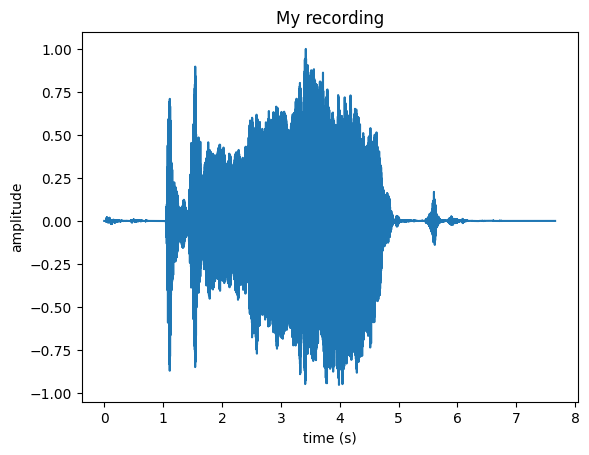

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio

fname = "my_voice.wav"   # change to your file name

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.astype(float)
    if x.ndim > 1:                    # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))         # normalise to [-1, 1]
else:                                 # fallback test signal
    print("File not found, using test signal")
    fs = 16000
    t = np.arange(0, 5, 1/fs)
    x = 0.5 * np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

Audio(x, rate=fs)   # play it in the notebook

01. Sampling rate is  48000Hz
number of samples are 2880000

02. x(n) is a discrete-time signal, defined only at integer values of n. It has no value between n = 2 and n = 3.

03. If h(n) = (1.1)ⁿ u(n) were an impulse response, the system would not be BIBO (bounded-input bounded-output) stable.

A system is BIBO stable only if its impulse response is absolutely summable:

Σ |h(n)| < ∞

For h(n) = aⁿ u(n), this sum is a geometric series. It converges to 1/(1−|a|) only when |a| < 1. For a = 1.1 the terms keep growing, so the sum diverges to infinity. A bounded input, such as a constant, would then produce an output that grows without bound.
